# Extra functions: exchange data with R

R viewmastR's `make3file()` writes a Seurat object as a Cell Ranger-style folder (the
"3file" format) plus metadata, embeddings and variable genes. py-viewmastR reads that
folder into AnnData (`read_3file()`) and writes AnnData back out for R (`write_3file()`).
This tutorial follows the R article [Extra functions](https://furlan-lab.github.io/viewmastR/articles/Extras.html).

| Role | Dataset |
|---|---|
| Example object | CD34+ enriched bone marrow, multiome RNA (Persad et al. 2023, Zenodo 6383269) |

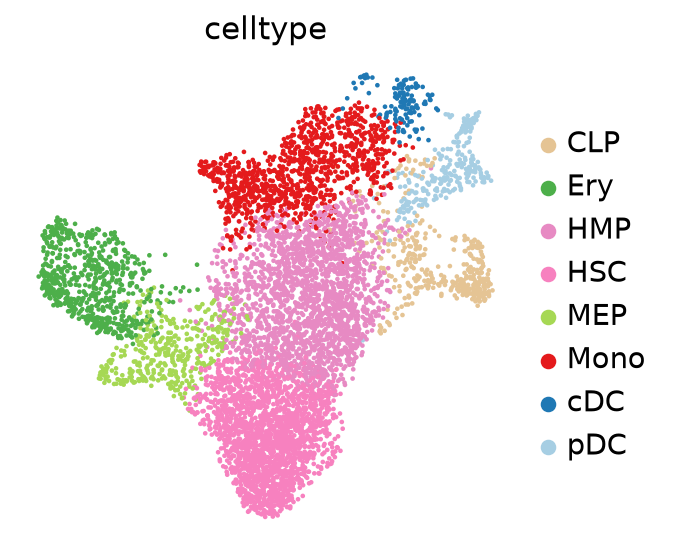

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
adata = td.multiome_rna("cd34")
sc.pl.umap(adata, color="celltype")

## Write a 3file folder

In R, `make3file(seu, dir = "out")` writes the same layout from a Seurat object.

In [2]:
vm.calculate_feature_dispersion(adata)
vm.select_features(adata, top_n=2000)
out = Path(tempfile.mkdtemp())
folder = vm.write_3file(adata, out, variable_features=vm.get_selected_features(adata))
print(sorted(p.name for p in folder.iterdir()))

['barcodes.tsv.gz', 'features.tsv.gz', 'matrix.mtx.gz', 'meta.csv', 'umap_reduction.tsv.gz', 'variablefeatures.tsv.gz']


## Read it back

`read_3file()` restores counts, metadata, embeddings (as `obsm["X_<name>"]`) and the
variable-gene flags. In R, `Read10X()` plus `read.csv("meta.csv")` rebuilds a Seurat object.

AnnData object with n_obs × n_vars = 6881 × 12464
    obs: 'celltype'
    var: 'variable_feature'
    obsm: 'X_umap'
    layers: None (.X)


counts and UMAP identical: True


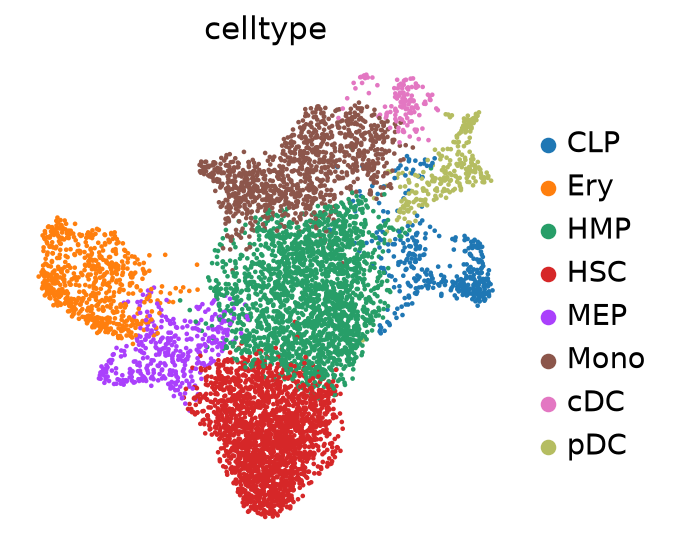

In [3]:
back = vm.read_3file(out)
print(back)
same = (back.X != adata.X).nnz == 0 and np.allclose(back.obsm["X_umap"], adata.obsm["X_umap"])
print("counts and UMAP identical:", same)
sc.pl.umap(back, color="celltype")

## Versions

In [4]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
